# Section B — Financial analysis

The first three code cells are unchanged copies of the source notebook's upload, Section A data-quality/tag setup, and characteristic-index cells. Run them first to create df, tags, and prod_idx in this notebook's own runtime. Their saved outputs are preserved. For grading, skip past this prerequisite block to the SECTION B heading. All Section B code, explanations, and outputs are unchanged.

In [90]:
import os
import pandas as pd

FILE = "stories_transactions.csv"

# Upload the CSV if it isn't in Colab's file panel yet
if not os.path.exists(FILE):
    from google.colab import files
    uploaded = files.upload()                  # pick your CSV
    os.rename(next(iter(uploaded)), FILE)      # keep the name the rest of the code expects

# Load the data
df = pd.read_csv(FILE)
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")

#Customer ID dropped after the randomness test
df = df.drop(columns=["Customer ID"])
print(f"After dropping Customer ID: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Loaded 51,177 rows x 14 columns
After dropping Customer ID: 51,177 rows x 13 columns


,Transaction ID,Date,Time,Branch,Order Type,Product,Category,Quantity,Unit Price (USD),Discount Rate,Unit Cost (USD),Line Revenue (USD),Line Gross Profit (USD)
0,SYN-0000001,2026-01-01,22:37:35,Harbour,Takeaway,Fresh Orange Juice,Cold Drinks,1,6.04,0.0,2.12,6.04,3.92
1,SYN-0000002,2026-01-01,17:34:07,Garden,Dine-in,Egg Sandwich,Breakfast,1,8.15,0.0,4.45,8.15,3.70
2,SYN-0000003,2026-01-01,22:45:29,Harbour,Dine-in,Brownie,Desserts,1,5.41,0.0,2.37,5.41,3.04
3,SYN-0000004,2026-01-01,21:36:38,Uptown,Dine-in,Iced Mocha,Cold Coffee,1,6.00,0.0,2.14,6.00,3.86
4,SYN-0000005,2026-01-01,12:34:01,Harbour,Dine-in,Classic Matcha,Matcha & Tea,1,6.77,0.0,2.27,6.77,4.50


In [99]:
# ===== Section A: data quality checks =====
import numpy as np, pandas as pd
raw = pd.read_csv("stories_transactions.csv")          # reload WITH Customer ID for the test below

# 1) Duplicates: count, then drop (assumption: identical lines are double entries)
print("Exact duplicate lines:", raw.duplicated().sum())
raw = raw.drop_duplicates().reset_index(drop=True)
print("Rows after dropping duplicates:", len(raw))

# 2) Missing values: only Customer ID has any
print(raw.isna().sum()[raw.isna().sum() > 0])

# 3) Arithmetic: revenue and gross profit follow the formulas on every row
rev = (raw["Quantity"] * raw["Unit Price (USD)"] * (1 - raw["Discount Rate"])).round(2)
gp  = (raw["Line Revenue (USD)"] - raw["Quantity"] * raw["Unit Cost (USD)"]).round(2)
print("Revenue mismatches:", (abs(rev - raw["Line Revenue (USD)"]) > 0.011).sum(),
      "| Gross profit mismatches:", (abs(gp - raw["Line Gross Profit (USD)"]) > 0.011).sum())

# 4) One fixed price and cost per product per branch, all six months
n = raw.groupby(["Product", "Branch"])[["Unit Price (USD)", "Unit Cost (USD)"]].nunique()
print("Product-branch pairs with more than one price or cost:", int((n > 1).any(axis=1).sum()), "of", len(n))
cost = raw.groupby(["Product", "Branch"])["Unit Cost (USD)"].first().unstack()
ratio = cost["Garden"] / cost["Harbour"]
print(f"Garden cost / Harbour cost: min {ratio.min():.3f}, max {ratio.max():.3f} (every product)")
m = raw.groupby("Branch")[["Line Gross Profit (USD)", "Line Revenue (USD)"]].sum()
print("Gross margin by branch:", (m.iloc[:, 0] / m.iloc[:, 1]).round(3).to_dict())

# 5) Customer IDs: does a customer behave consistently? Compare with randomly shuffled IDs
rng = np.random.default_rng(0)
def top_share(d, col, min_n):
    s = d.groupby("Customer ID")[col].agg(lambda x: x.value_counts().iloc[0] / len(x))
    k = d.groupby("Customer ID").size()
    return s[k >= min_n].mean()
tx = raw.drop_duplicates("Transaction ID").dropna(subset=["Customer ID"])
ln = raw.dropna(subset=["Customer ID"])
for name, d, col, k in [("favorite branch", tx, "Branch", 5), ("favorite product", ln, "Product", 8)]:
    real = top_share(d, col, k)
    fake = np.mean([top_share(d.assign(**{col: rng.permutation(d[col].values)}), col, k) for _ in range(10)])
    print(f"Share of visits to {name}: real customers {real:.3f} vs shuffled IDs {fake:.3f}")
print(
    "Customer-ID checks: the observed average favourite-branch and "
    "favourite-product shares are similar to the averages from ten "
    "shuffled comparisons. These limited checks do not prove that IDs "
    "are random or unusable. We exclude Customer ID from the working "
    "analysis pending validation of its meaning and reliability."
)
df = raw.drop(columns=["Customer ID"])

# ===== Product characteristics (assumption: our own tagging) =====
T = {  # product: (temperature, food_or_drink, milk, sweet, caffeine, perishable)
 "Almond Croissant":("ambient","food",0,1,0,1), "Banana Bread":("ambient","food",0,1,0,1),
 "Blueberry Muffin":("ambient","food",0,1,0,1), "Butter Croissant":("ambient","food",0,0,0,1),
 "Chocolate Cookie":("ambient","food",0,1,0,1), "Chocolate Croissant":("ambient","food",0,1,0,1),
 "Cinnamon Roll":("ambient","food",0,1,0,1), "Pistachio Cookie":("ambient","food",0,1,0,1),
 "Avocado Toast":("hot","food",0,0,0,1), "Egg Sandwich":("hot","food",0,0,0,1),
 "Granola Yoghurt":("cold","food",1,1,0,1), "Coffee Frappe":("cold","drink",1,1,1,0),
 "Cold Brew":("cold","drink",0,0,1,0), "Iced Americano":("cold","drink",0,0,1,0),
 "Iced Latte":("cold","drink",1,0,1,0), "Iced Mocha":("cold","drink",1,1,1,0),
 "Fresh Orange Juice":("cold","drink",0,1,0,1), "Lemonade":("cold","drink",0,1,0,0),
 "Peach Iced Tea":("cold","drink",0,1,1,0), "Sparkling Water":("cold","drink",0,0,0,0),
 "Still Water":("cold","drink",0,0,0,0), "Brownie":("ambient","food",0,1,0,1),
 "Cheesecake Slice":("cold","food",1,1,0,1), "Frozen Yoghurt Cup":("cold","food",1,1,0,1),
 "Tiramisu Cup":("cold","food",1,1,1,1), "Americano":("hot","drink",0,0,1,0),
 "Cappuccino":("hot","drink",1,0,1,0), "Caramel Latte":("hot","drink",1,1,1,0),
 "Espresso":("hot","drink",0,0,1,0), "Flat White":("hot","drink",1,0,1,0),
 "Spanish Latte":("hot","drink",1,1,1,0), "Vanilla Latte":("hot","drink",1,1,1,0),
 "Chai Latte":("hot","drink",1,1,1,0), "Classic Matcha":("hot","drink",1,0,1,0),
 "English Breakfast Tea":("hot","drink",0,0,1,0), "Iced Matcha":("cold","drink",1,0,1,0),
 "Mint Tea":("hot","drink",0,0,0,0), "Strawberry Matcha":("cold","drink",1,1,1,0),
 "Chicken Salad Bowl":("cold","food",0,0,0,1), "Quinoa Bowl":("cold","food",0,0,0,1),
 "Soup of the Day":("hot","food",0,0,0,1), "Chicken Pesto Sandwich":("hot","food",0,0,0,1),
 "Halloumi Wrap":("hot","food",0,0,0,1), "Tuna Sandwich":("cold","food",0,0,0,1),
 "Turkey & Cheese Sandwich":("cold","food",0,0,0,1),
}
tags = pd.DataFrame.from_dict(T, orient="index", columns=["temperature","type","milk","sweet","caffeine","perishable"])
tags.index.name = "Product"
price = df.groupby("Product")["Unit Price (USD)"].mean()
tags["price_tier"] = pd.qcut(price, 3, labels=["low","mid","high"])
tags["category"] = df.groupby("Product")["Category"].first()
assert set(tags.index) == set(df["Product"].unique())
tags.to_csv("product_tags.csv")
print(tags.head())

Exact duplicate lines: 132
Rows after dropping duplicates: 51045
Customer ID    18646
dtype: int64
Revenue mismatches: 0 | Gross profit mismatches: 0
Product-branch pairs with more than one price or cost: 0 of 135
Garden cost / Harbour cost: min 1.426, max 1.439 (every product)
Gross margin by branch: {'Garden': 0.469, 'Harbour': 0.65, 'Uptown': 0.626}
Share of visits to favorite branch: real customers 0.571 vs shuffled IDs 0.568
Share of visits to favorite product: real customers 0.165 vs shuffled IDs 0.170
Customer-ID checks: the observed average favourite-branch and favourite-product shares are similar to the averages from ten shuffled comparisons. These limited checks do not prove that IDs are random or unusable. We exclude Customer ID from the working analysis pending validation of its meaning and reliability.
                 temperature  type  milk  sweet  caffeine  perishable  \
Product                                                                 
Almond Croissant     ambien

Chi-square test of product mix vs branch: chi2=438, dof=88, p=5.7e-48
                          Garden  Harbour  Uptown     category
Product                                                       
Halloumi Wrap               90.0     87.0   151.0   Sandwiches
Chicken Pesto Sandwich      93.0     89.0   141.0   Sandwiches
Turkey & Cheese Sandwich    90.0     92.0   137.0   Sandwiches
Tuna Sandwich               88.0     95.0   134.0   Sandwiches
Quinoa Bowl                104.0     90.0   119.0        Meals
Still Water                 94.0    100.0   111.0  Cold Drinks


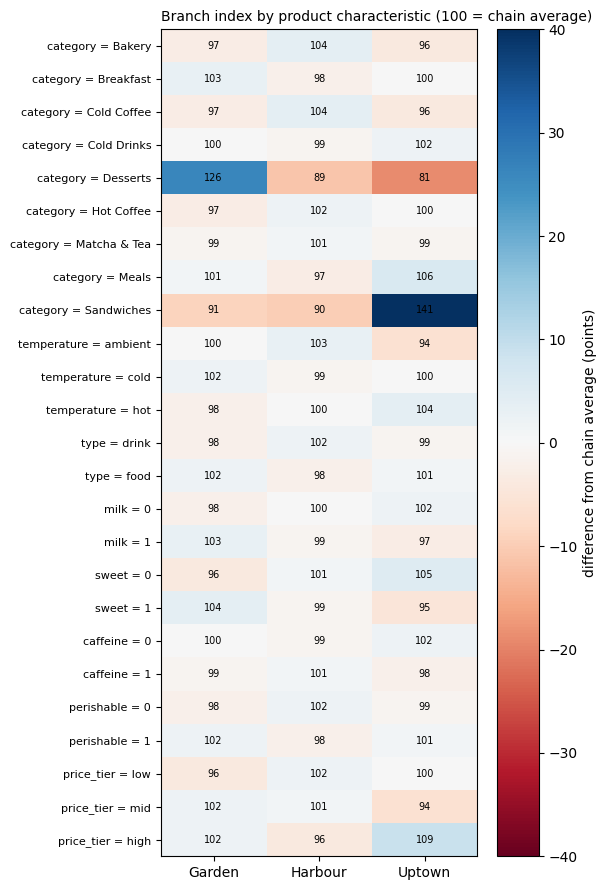

In [100]:
# ===== Characteristic comparison: what sells unusually well or badly at each branch =====
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

units = df.pivot_table(index="Product", columns="Branch", values="Quantity", aggfunc="sum")

# Is the product mix different between branches, beyond chance?
chi2, p, dof, _ = chi2_contingency(units.values)
print(f"Chi-square test of product mix vs branch: chi2={chi2:.0f}, dof={dof}, p={p:.1e}")

# Branch index per product: 100 = sells exactly its chain-wide share; 140 = 40% more than expected
def index_table(units_by_group):
    branch_share = units_by_group / units_by_group.sum()
    chain_share = units_by_group.sum(axis=1) / units_by_group.values.sum()
    return (branch_share.div(chain_share, axis=0) * 100).round(0)

prod_idx = index_table(units).join(tags["category"])
print(prod_idx.sort_values("Uptown", ascending=False).head(6))

# Same index, grouped by each characteristic
rows = []
for col in ["category", "temperature", "type", "milk", "sweet", "caffeine", "perishable", "price_tier"]:
    g = units.join(tags[col]).groupby(col, observed=True).sum()
    idx = index_table(g)
    idx.index = [f"{col} = {v}" for v in idx.index]
    rows.append(idx)
char_idx = pd.concat(rows)
char_idx.to_csv("branch_characteristic_index.csv")

# Heatmap
fig, ax = plt.subplots(figsize=(6, 0.32 * len(char_idx) + 1))
im = ax.imshow(char_idx.values - 100, cmap="RdBu", vmin=-40, vmax=40, aspect="auto")
ax.set_xticks(range(3), char_idx.columns); ax.set_yticks(range(len(char_idx)), char_idx.index, fontsize=8)
for i in range(char_idx.shape[0]):
    for j in range(3):
        ax.text(j, i, f"{char_idx.values[i, j]:.0f}", ha="center", va="center", fontsize=7)
ax.set_title("Branch index by product characteristic (100 = chain average)", fontsize=10, loc="left")
fig.colorbar(im, ax=ax, label="difference from chain average (points)")
plt.tight_layout(); plt.show()

# **SECTION B**

In [102]:
# ===== Section B inputs (built in Section A) =====
from IPython.display import display

inputs = {"df": df, "tags": tags, "prod_idx": prod_idx}
overview = pd.DataFrame({
    "rows": [t.shape[0] for t in inputs.values()],
    "columns": [t.shape[1] for t in inputs.values()],
    "missing values": [int(t.isna().sum().sum()) for t in inputs.values()],
    "column names": [", ".join(map(str, t.columns)) for t in inputs.values()],
}, index=inputs.keys())
print("Overview of the tables Section B uses:")
display(overview)

print(f"Branches: {', '.join(sorted(df['Branch'].unique()))}  |  Dates: {df['Date'].min()} to {df['Date'].max()}")

for name, t in inputs.items():
    print(f"\n{name}: first 3 rows")
    display(t.head(3))

Overview of the tables Section B uses:


,rows,columns,missing values,column names
df,51045,13,0,"Transaction ID, Date, Time, Branch, Order Type..."
tags,45,8,0,"temperature, type, milk, sweet, caffeine, peri..."
prod_idx,45,4,0,"Garden, Harbour, Uptown, category"


Branches: Garden, Harbour, Uptown  |  Dates: 2026-01-01 to 2026-06-30

df: first 3 rows


,Transaction ID,Date,Time,Branch,Order Type,Product,Category,Quantity,Unit Price (USD),Discount Rate,Unit Cost (USD),Line Revenue (USD),Line Gross Profit (USD)
0,SYN-0000001,2026-01-01,22:37:35,Harbour,Takeaway,Fresh Orange Juice,Cold Drinks,1,6.04,0.0,2.12,6.04,3.92
1,SYN-0000002,2026-01-01,17:34:07,Garden,Dine-in,Egg Sandwich,Breakfast,1,8.15,0.0,4.45,8.15,3.70
2,SYN-0000003,2026-01-01,22:45:29,Harbour,Dine-in,Brownie,Desserts,1,5.41,0.0,2.37,5.41,3.04



tags: first 3 rows


,temperature,type,milk,sweet,caffeine,perishable,price_tier,category
Product,,,,,,,,
Almond Croissant,ambient,food,0,1,0,1,mid,Bakery
Banana Bread,ambient,food,0,1,0,1,mid,Bakery
Blueberry Muffin,ambient,food,0,1,0,1,low,Bakery



prod_idx: first 3 rows


,Garden,Harbour,Uptown,category
Product,,,,
Almond Croissant,97.0,108.0,85.0,Bakery
Americano,92.0,104.0,103.0,Hot Coffee
Avocado Toast,102.0,97.0,103.0,Breakfast


In [103]:
# SECTION B1 — Slow perishables
import pandas as pd
import numpy as np
from IPython.display import display

# Work on a separate copy.
b1_data = df.copy()
b1_data["Date"] = pd.to_datetime(
    b1_data["Date"], format="%Y-%m-%d", errors="raise"
).dt.normalize()

# Validate inputs before calculating.
b1_required = [
    "Date", "Branch", "Product", "Quantity",
    "Unit Cost (USD)", "Line Revenue (USD)", "Line Gross Profit (USD)"
]
assert b1_data[b1_required].notna().all().all(), "Missing required values."
assert tags.index.is_unique, "tags has duplicate product names."
assert tags["perishable"].isin([0, 1]).all(), "Unexpected perishable tags."
assert b1_data["Product"].isin(tags.index).all(), "Some products lack tags."
assert (b1_data["Quantity"] > 0).all(), "Review zero/negative quantities."
assert (b1_data["Unit Cost (USD)"] > 0).all(), "Review non-positive costs."

b1_data["sold_cost"] = (
    b1_data["Quantity"] * b1_data["Unit Cost (USD)"]
)
b1_gp_error = (
    b1_data["Line Gross Profit (USD)"]
    - (b1_data["Line Revenue (USD)"] - b1_data["sold_cost"])
).abs()

assert b1_gp_error.max() <= 0.011, (
    "Recorded gross profit does not reconcile within $0.01 per line."
)

# Use the entire observed calendar period, including zero-sale product days.
b1_start = b1_data["Date"].min()
b1_end = b1_data["Date"].max()
b1_days = (b1_end - b1_start).days + 1

b1_branch = b1_data.groupby("Branch").agg(
    observed_days=("Date", "nunique"),
    total_units=("Quantity", "sum"),
    observed_products=("Product", "nunique")
)
b1_branch["calendar_days"] = b1_days
b1_branch["days_without_records"] = b1_days - b1_branch["observed_days"]
b1_branch["branch_units_per_day"] = b1_branch["total_units"] / b1_days

print(f"B1 period: {b1_start.date()} to {b1_end.date()} ({b1_days} days)")
print("Branch coverage and sales volume:")
display(b1_branch.round(3))

if b1_branch["days_without_records"].gt(0).any():
    print(
        "CAUTION: Some branch-days have no records. Calendar-day averages "
        "treat these as zero sales; verify closures or missing data."
    )

# Use the team's existing perishable classification.
b1_products = tags.index[tags["perishable"].eq(1)]
assert len(b1_products) > 0, "No products are tagged perishable."

print("\nProducts classified as perishable by the team's tags:")
display(tags.loc[b1_products, ["category", "perishable"]])

# Include every branch × perishable product, even if it never sold there.
b1_grid = pd.MultiIndex.from_product(
    [b1_branch.index, b1_products], names=["Branch", "Product"]
)

b1 = (
    b1_data[b1_data["Product"].isin(b1_products)]
    .groupby(["Branch", "Product"])
    .agg(
        units=("Quantity", "sum"),
        revenue=("Line Revenue (USD)", "sum"),
        gross_profit=("Line Gross Profit (USD)", "sum"),
        sold_cost=("sold_cost", "sum"),
        selling_days=("Date", "nunique")
    )
    .reindex(b1_grid, fill_value=0)
    .reset_index()
)

b1["category"] = b1["Product"].map(tags["category"])
b1["units_per_day"] = b1["units"] / b1_days
b1["gross_profit_per_day_usd"] = b1["gross_profit"] / b1_days
b1["zero_sale_days"] = b1_days - b1["selling_days"]

# Quantity-weighted cost; unknown where a product has no recorded sales.
b1["weighted_unit_cost_usd"] = (
    b1["sold_cost"] / b1["units"].replace(0, np.nan)
)

# Waste units/day that would consume all recorded daily gross profit.
# Assumes discarded units cost the same as sold units.
b1["break_even_waste_units_per_day"] = (
    b1["gross_profit_per_day_usd"]
    / b1["weighted_unit_cost_usd"]
).where(b1["gross_profit_per_day_usd"].ge(0))

# Scenario only: exactly one additional discarded unit per calendar day.
b1["gp_after_1_wasted_unit_per_day_usd"] = (
    b1["gross_profit_per_day_usd"] - b1["weighted_unit_cost_usd"]
)

# Adjust for branch size using total units sold across the entire menu.
b1["branch_total_units"] = b1["Branch"].map(b1_branch["total_units"])
b1["units_per_1000_branch_units"] = (
    1000 * b1["units"] / b1["branch_total_units"]
)

# Compare each product's sales share with the OTHER TWO branches pooled.
b1_product_totals = b1_data.groupby("Product")["Quantity"].sum()
b1_total_units = b1_data["Quantity"].sum()

b1["other_branch_product_units"] = (
    b1["Product"].map(b1_product_totals).fillna(0) - b1["units"]
)
b1["other_branch_total_units"] = (
    b1_total_units - b1["branch_total_units"]
)
b1["other_branch_units_per_1000"] = (
    1000 * b1["other_branch_product_units"]
    / b1["other_branch_total_units"]
)
b1["relative_demand_index"] = (
    100 * b1["units_per_1000_branch_units"]
    / b1["other_branch_units_per_1000"].replace(0, np.nan)
)
b1["expected_units_per_day_at_peer_mix"] = (
    b1["branch_total_units"] / b1_days
    * b1["other_branch_units_per_1000"] / 1000
)

# Strictly fewer than 1 unit/day, evaluated before rounding.
b1["slow"] = b1["units_per_day"].lt(1)
b1_slow = b1.loc[b1["slow"]].sort_values(
    ["Branch", "units_per_day", "Product"]
).copy()

print("\nSlow perishable counts by branch:")
display(
    b1.groupby("Branch").agg(
        perishable_products=("Product", "size"),
        slow_perishable_products=("slow", "sum")
    )
)

print("\nSlow perishables — economics and branch-volume adjustment:")
b1_columns = [
    "Branch", "Product", "category", "units", "units_per_day",
    "zero_sale_days", "gross_profit_per_day_usd",
    "weighted_unit_cost_usd", "break_even_waste_units_per_day",
    "gp_after_1_wasted_unit_per_day_usd",
    "units_per_1000_branch_units", "other_branch_units_per_1000",
    "relative_demand_index", "expected_units_per_day_at_peer_mix"
]
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(b1_slow[b1_columns].round(3))

# Show the same flagged products across all branches for direct comparison.
b1_flagged_products = b1_slow["Product"].unique()
print("\nCross-branch comparison of products flagged anywhere:")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(
        b1[b1["Product"].isin(b1_flagged_products)]
        .pivot(
            index="Product",
            columns="Branch",
            values=["units_per_day", "units_per_1000_branch_units"]
        )
        .round(3)
    )

print("""
INTERPRETATION
• Relative demand index = 100: same product sales share as the other branches.
  Below 100: lower share; above 100: higher share.
• If expected units/day at peer mix is also below 1, branch volume can
  explain crossing the slow-sales threshold even at the peers' sales mix.
• A lower normalized share suggests weaker relative sales, but does not
  prove weak customer demand: availability and stockouts are unobserved.
• Break-even waste is a hypothetical threshold, NOT measured waste.
  Gross profit excludes any unrecorded waste and operating overhead.
• Negative gross profit means the product already loses gross profit
  before additional waste. Missing cost/threshold values mean insufficient
  local sales data to estimate them.
• No-record product days count as zero sales; continuous menu availability
  and the team's perishable tags still need to be valid.
""")

B1 period: 2026-01-01 to 2026-06-30 (181 days)
Branch coverage and sales volume:


,observed_days,total_units,observed_products,calendar_days,days_without_records,branch_units_per_day
Branch,,,,,,
Garden,181,17795,45,181,0,98.315
Harbour,181,26025,45,181,0,143.785
Uptown,181,10135,45,181,0,55.994



Products classified as perishable by the team's tags:


,category,perishable
Product,,
Almond Croissant,Bakery,1
Banana Bread,Bakery,1
Blueberry Muffin,Bakery,1
Butter Croissant,Bakery,1
Chocolate Cookie,Bakery,1
Chocolate Croissant,Bakery,1
Cinnamon Roll,Bakery,1
Pistachio Cookie,Bakery,1
Avocado Toast,Breakfast,1



Slow perishable counts by branch:


...


Slow perishables — economics and branch-volume adjustment:


,Branch,Product,category,units,units_per_day,zero_sale_days,gross_profit_per_day_usd,weighted_unit_cost_usd,break_even_waste_units_per_day,gp_after_1_wasted_unit_per_day_usd,units_per_1000_branch_units,other_branch_units_per_1000,relative_demand_index,expected_units_per_day_at_peer_mix
18,Garden,Soup of the Day,Meals,149,0.823,88,2.582,3.99,0.647,-1.408,8.373,8.296,100.924,0.816
17,Garden,Quinoa Bowl,Meals,172,0.950,77,4.330,7.04,0.615,-2.710,9.666,9.126,105.912,0.897
16,Garden,Chicken Salad Bowl,Meals,179,0.989,70,4.253,8.08,0.526,-3.827,10.059,10.315,97.516,1.014
64,Uptown,Soup of the Day,Meals,75,0.414,126,1.721,2.68,0.642,-0.959,7.400,8.535,86.704,0.478
56,Uptown,Granola Yoghurt,Breakfast,107,0.591,102,2.555,3.19,0.801,-0.635,10.557,10.680,98.852,0.598
62,Uptown,Chicken Salad Bowl,Meals,111,0.613,106,3.991,5.42,0.736,-1.429,10.952,10.064,108.826,0.564
63,Uptown,Quinoa Bowl,Meals,112,0.619,101,3.960,4.72,0.839,-0.760,11.051,8.900,124.166,0.498
48,Uptown,Blueberry Muffin,Bakery,150,0.829,79,2.082,1.26,1.652,0.822,14.800,17.754,83.360,0.994
61,Uptown,Tiramisu Cup,Desserts,163,0.901,86,3.173,2.74,1.158,0.433,16.083,19.831,81.099,1.110
54,Uptown,Avocado Toast,Breakfast,175,0.967,71,4.807,4.01,1.199,0.797,17.267,16.613,103.933,0.930



Cross-branch comparison of products flagged anywhere:


units_per_day                units_per_1000_branch_units  \
Branch                    Garden Harbour Uptown                      Garden   
Product                                                                       
Avocado Toast              1.680   2.343  0.967                      17.083   
Blueberry Muffin           1.762   2.536  0.829                      17.926   
Brownie                    3.055   3.232  0.989                      31.076   
Chicken Salad Bowl         0.989   1.448  0.613                      10.059   
Fresh Orange Juice         1.856   2.685  0.994                      18.882   
Frozen Yoghurt Cup         2.674   2.508  0.989                      27.199   
Granola Yoghurt            1.033   1.552  0.591                      10.509   
Quinoa Bowl                0.950   1.204  0.619                       9.666   
Soup of the Day            0.823   1.243  0.414                       8.373   
Tiramisu Cup               2.492   2.309  0.901                      25.344   

                                    
Branch             Harbour  Uptown  
Product                             
Avocado Toast       16.292  17.267  
Blueberry Muffin    17.637  14.800  
Brownie             22.478  17.662  
Chicken Salad Bowl  10.067  10.952  
Fresh Orange Juice  18.674  17.760  
Frozen Yoghurt Cup  17.445  17.662  
Granola Yoghurt     10.797  10.557  
Quinoa Bowl          8.377  11.051  
Soup of the Day      8.646   7.400  
Tiramisu Cup        16.061  16.083


INTERPRETATION
• Relative demand index = 100: same product sales share as the other branches.
  Below 100: lower share; above 100: higher share.
• If expected units/day at peer mix is also below 1, branch volume can
  explain crossing the slow-sales threshold even at the peers' sales mix.
• A lower normalized share suggests weaker relative sales, but does not
  prove weak customer demand: availability and stockouts are unobserved.
• Break-even waste is a hypothetical threshold, NOT measured waste.
  Gross profit excludes any unrecorded waste and operating overhead.
• Negative gross profit means the product already loses gross profit
  before additional waste. Missing cost/threshold values mean insufficient
  local sales data to estimate them.
• No-record product days count as zero sales; continuous menu availability
  and the team's perishable tags still need to be valid.



In [104]:
# Lowest gross profit per unit among ALL 45 products, per branch
gp_unit = (df.groupby(["Branch", "Product"])[["Line Gross Profit (USD)", "Quantity"]].sum()
             .assign(gp_per_unit=lambda d: d["Line Gross Profit (USD)"] / d["Quantity"])["gp_per_unit"])
print(gp_unit.groupby(level="Branch", group_keys=False).nsmallest(4).round(2))

Branch   Product         
Garden   Sparkling Water     0.80
         Still Water         1.01
         Espresso            1.71
         Brownie             1.73
Harbour  Still Water         1.39
         Sparkling Water     1.52
         Espresso            2.11
         Chocolate Cookie    2.38
Uptown   Still Water         1.24
         Sparkling Water     1.33
         Espresso            1.91
         Chocolate Cookie    2.13
Name: gp_per_unit, dtype: float64


In [105]:
# SECTION B2 — Validate baskets and examine water/espresso co-purchases.
# Leaves df, tags, and prod_idx unchanged.
import pandas as pd
import numpy as np
from IPython.display import display

b2_data = df.copy()
b2_required = [
    "Transaction ID", "Branch", "Date", "Product",
    "Quantity", "Line Gross Profit (USD)"
]
assert b2_data[b2_required].notna().all().all(), "Missing required values."
assert b2_data["Quantity"].gt(0).all(), "Review non-positive quantities."

# Check whether an ID consistently identifies one branch and date.
b2_id_check = b2_data.groupby("Transaction ID").agg(
    branches=("Branch", "nunique"),
    dates=("Date", "nunique"),
    rows=("Product", "size"),
    distinct_products=("Product", "nunique")
)

print("TRANSACTION-ID AUDIT")
display(pd.Series({
    "data_rows": len(b2_data),
    "unique_transaction_ids": len(b2_id_check),
    "ids_with_multiple_rows": int(b2_id_check["rows"].gt(1).sum()),
    "ids_with_multiple_products": int(
        b2_id_check["distinct_products"].gt(1).sum()
    ),
    "ids_spanning_multiple_branches": int(b2_id_check["branches"].gt(1).sum()),
    "ids_spanning_multiple_dates": int(b2_id_check["dates"].gt(1).sum())
}, name="Count").to_frame())

# Identify actual names rather than assuming "Water" exists.
b2_targets = sorted(
    b2_data.loc[
        b2_data["Product"].str.contains(
            r"\bwater\b|\bespresso\b", case=False, regex=True, na=False
        ),
        "Product"
    ].unique()
)
print("\nMatched water/espresso products:", b2_targets)

# Verify their recorded gross profit per unit, even if baskets are unavailable.
b2_product_profit = b2_data.groupby(["Branch", "Product"]).agg(
    units=("Quantity", "sum"),
    gross_profit_usd=("Line Gross Profit (USD)", "sum")
)
b2_product_profit["gp_per_unit_usd"] = (
    b2_product_profit["gross_profit_usd"] / b2_product_profit["units"]
)
b2_product_profit["gp_per_unit_rank_lowest_first"] = (
    b2_product_profit.groupby(level="Branch")["gp_per_unit_usd"]
    .rank(method="min")
)

print("\nTarget-product profitability (rank 1 = lowest GP per unit):")
display(
    b2_product_profit[
        b2_product_profit.index.get_level_values("Product").isin(b2_targets)
    ].round(3)
)

if b2_id_check[["branches", "dates"]].gt(1).any().any():
    print(
        "\nSTOP: Some transaction IDs span branches or dates. "
        "We must verify the receipt identifier before interpreting baskets."
    )

elif b2_id_check["rows"].eq(1).all():
    print(
        "\nBASKET ANALYSIS NOT IDENTIFIABLE FROM THESE RECORDS:\n"
        "Every Transaction ID occurs on exactly one row. This could mean "
        "single-product receipts or IDs assigned to individual line items.\n"
        "We cannot distinguish those possibilities from this table, so we "
        "cannot conclude that water/espresso are bought alone or as add-ons.\n"
        "We need a receipt/order ID shared by all items in the same purchase. "
        "Do not manufacture baskets by grouping nearby timestamps."
    )

elif not b2_targets:
    print("\nNo water/espresso product names matched; inspect the menu names.")

else:
    # One row per product per candidate basket: handles repeated product lines.
    b2_items = b2_data.groupby(
        ["Branch", "Transaction ID", "Product"], as_index=False
    ).agg(
        units=("Quantity", "sum"),
        product_gp=("Line Gross Profit (USD)", "sum")
    )
    b2_items["positive_gp_product"] = b2_items["product_gp"].gt(0)

    b2_baskets = b2_items.groupby(
        ["Branch", "Transaction ID"], as_index=False
    ).agg(
        distinct_products=("Product", "nunique"),
        basket_gp=("product_gp", "sum"),
        positive_gp_products=("positive_gp_product", "sum")
    )

    b2_focal = b2_items[b2_items["Product"].isin(b2_targets)].merge(
        b2_baskets,
        on=["Branch", "Transaction ID"],
        how="left",
        validate="many_to_one"
    )
    b2_focal["has_other_product"] = b2_focal["distinct_products"].gt(1)
    b2_focal["has_profitable_other_product"] = (
        b2_focal["positive_gp_products"]
        - b2_focal["positive_gp_product"].astype(int)
    ).gt(0)
    b2_focal["other_items_gp"] = (
        b2_focal["basket_gp"] - b2_focal["product_gp"]
    )

    b2_summary = b2_focal.groupby(["Branch", "Product"]).agg(
        baskets_containing_product=("Transaction ID", "size"),
        pct_with_other_product=("has_other_product", "mean"),
        pct_with_profitable_other_product=(
            "has_profitable_other_product", "mean"
        ),
        mean_target_gp_per_basket_usd=("product_gp", "mean"),
        mean_other_items_gp_per_basket_usd=("other_items_gp", "mean"),
        mean_total_basket_gp_usd=("basket_gp", "mean")
    )
    b2_pct_cols = [
        "pct_with_other_product", "pct_with_profitable_other_product"
    ]
    b2_summary[b2_pct_cols] *= 100

    print("\nCO-PURCHASE RESULTS — conditional on Transaction ID being a receipt ID")
    with pd.option_context("display.max_columns", None):
        display(b2_summary.round(3))

    print(
        "\nProfitable other product = a different product with positive "
        "recorded gross profit in that basket.\n"
        "Other-item GP excludes all units of the focal product and includes "
        "both positive and negative GP from the remaining items.\n"
        "These are associations: companion-item profit is not profit caused "
        "by stocking water or espresso. Product summaries can overlap and "
        "must not be added together."
    )

TRANSACTION-ID AUDIT


,Count
data_rows,51045
unique_transaction_ids,33887
ids_with_multiple_rows,15650
ids_with_multiple_products,15631
ids_spanning_multiple_branches,0
ids_spanning_multiple_dates,0



Matched water/espresso products: ['Espresso', 'Sparkling Water', 'Still Water']

Target-product profitability (rank 1 = lowest GP per unit):


units  gross_profit_usd  gp_per_unit_usd  \
Branch  Product                                                     
Garden  Espresso           212            362.21            1.709   
        Sparkling Water    336            269.85            0.803   
        Still Water        367            370.16            1.009   
Harbour Espresso           350            737.38            2.107   
        Sparkling Water    520            789.49            1.518   
        Still Water        575            799.34            1.390   
Uptown  Espresso           124            236.57            1.908   
        Sparkling Water    208            275.60            1.325   
        Still Water        247            306.09            1.239   

                         gp_per_unit_rank_lowest_first  
Branch  Product                                         
Garden  Espresso                                   3.0  
        Sparkling Water                            1.0  
        Still Water                                2.0  
Harbour Espresso                                   3.0  
        Sparkling Water                            2.0  
        Still Water                                1.0  
Uptown  Espresso                                   3.0  
        Sparkling Water                            2.0  
        Still Water                                1.0


CO-PURCHASE RESULTS — conditional on Transaction ID being a receipt ID


baskets_containing_product  pct_with_other_product  \
Branch  Product                                                               
Garden  Espresso                                202                  63.366   
        Sparkling Water                         322                  62.733   
        Still Water                             358                  65.363   
Harbour Espresso                                327                  66.055   
        Sparkling Water                         495                  64.040   
        Still Water                             533                  65.291   
Uptown  Espresso                                117                  63.248   
        Sparkling Water                         198                  60.606   
        Still Water                             237                  67.089   

                         pct_with_profitable_other_product  \
Branch  Product                                              
Garden  Espresso                                    63.366   
        Sparkling Water                             62.733   
        Still Water                                 65.363   
Harbour Espresso                                    66.055   
        Sparkling Water                             64.040   
        Still Water                                 65.291   
Uptown  Espresso                                    63.248   
        Sparkling Water                             60.606   
        Still Water                                 67.089   

                         mean_target_gp_per_basket_usd  \
Branch  Product                                          
Garden  Espresso                                 1.793   
        Sparkling Water                          0.838   
        Still Water                              1.034   
Harbour Espresso                                 2.255   
        Sparkling Water                          1.595   
        Still Water                              1.500   
Uptown  Espresso                                 2.022   
        Sparkling Water                          1.392   
        Still Water                              1.292   

                         mean_other_items_gp_per_basket_usd  \
Branch  Product                                               
Garden  Espresso                                      1.850   
        Sparkling Water                               2.002   
        Still Water                                   2.341   
Harbour Espresso                                      2.852   
        Sparkling Water                               3.207   
        Still Water                                   3.257   
Uptown  Espresso                                      2.646   
        Sparkling Water                               2.848   
        Still Water                                   3.083   

                         mean_total_basket_gp_usd  
Branch  Product                                    
Garden  Espresso                            3.643  
        Sparkling Water                     2.840  
        Still Water                         3.375  
Harbour Espresso                            5.107  
        Sparkling Water                     4.802  
        Still Water                         4.757  
Uptown  Espresso                            4.668  
        Sparkling Water                     4.240  
        Still Water                         4.374


Profitable other product = a different product with positive recorded gross profit in that basket.
Other-item GP excludes all units of the focal product and includes both positive and negative GP from the remaining items.
These are associations: companion-item profit is not profit caused by stocking water or espresso. Product summaries can overlap and must not be added together.


In [106]:
# SECTION B3A — Verify promotions and compare daily performance.
# Does not modify df, tags, or prod_idx.
import pandas as pd
import numpy as np
from IPython.display import display

b3_data = df.copy()
b3_data["Date"] = pd.to_datetime(
    b3_data["Date"], format="%Y-%m-%d", errors="raise"
).dt.normalize()

b3_required = [
    "Date", "Branch", "Category", "Quantity", "Discount Rate",
    "Unit Price (USD)", "Unit Cost (USD)",
    "Line Revenue (USD)", "Line Gross Profit (USD)"
]
assert b3_data[b3_required].notna().all().all(), "Missing required values."
assert b3_data["Quantity"].gt(0).all(), "Review non-positive quantities."
assert b3_data["Discount Rate"].between(0, 1).all(), (
    "Discount Rate must be a fraction between 0 and 1."
)

b3_branches = ["Harbour", "Garden", "Uptown"]
b3_categories = ["Cold Coffee", "Desserts"]
assert set(b3_branches).issubset(b3_data["Branch"].unique())
assert set(b3_categories).issubset(b3_data["Category"].unique())

# Check what the recorded prices and financial fields mean.
b3_data["list_value"] = (
    b3_data["Quantity"] * b3_data["Unit Price (USD)"]
)
b3_data["recorded_discount_usd"] = (
    b3_data["list_value"] - b3_data["Line Revenue (USD)"]
)
b3_revenue_error = (
    b3_data["Line Revenue (USD)"]
    - b3_data["list_value"] * (1 - b3_data["Discount Rate"])
).abs()
b3_gp_error = (
    b3_data["Line Gross Profit (USD)"]
    - (
        b3_data["Line Revenue (USD)"]
        - b3_data["Quantity"] * b3_data["Unit Cost (USD)"]
    )
).abs()

print("FINANCIAL FIELD CHECK")
display(pd.Series({
    "max_revenue_reconciliation_error_usd": b3_revenue_error.max(),
    "max_gp_reconciliation_error_usd": b3_gp_error.max()
}).to_frame("Value"))
assert b3_revenue_error.max() <= 0.011, "Revenue formula needs investigation."
assert b3_gp_error.max() <= 0.011, "Gross-profit formula needs investigation."

b3_events = {
    "March": (pd.Timestamp("2026-03-12"), pd.Timestamp("2026-03-19")),
    "May": (pd.Timestamp("2026-05-12"), pd.Timestamp("2026-05-19"))
}
b3_parts = []
b3_windows = []
b3_coverage = []

for event, (start, end) in b3_events.items():
    periods = {
        "Before": (start - pd.Timedelta(days=14), start - pd.Timedelta(days=1)),
        "Promotion": (start, end),
        "After": (end + pd.Timedelta(days=1), end + pd.Timedelta(days=14))
    }
    for period, (left, right) in periods.items():
        dates = pd.date_range(left, right)
        assert left >= b3_data["Date"].min()
        assert right <= b3_data["Date"].max()

        b3_windows.append({
            "Event": event, "Period": period,
            "Start": left.date(), "End": right.date(), "Days": len(dates)
        })
        window = b3_data[b3_data["Date"].between(left, right)].copy()

        for branch in b3_branches:
            recorded_dates = window.loc[
                window["Branch"].eq(branch), "Date"
            ].unique()
            b3_coverage.append({
                "Event": event, "Period": period, "Branch": branch,
                "days_without_any_branch_records": len(
                    dates.difference(pd.DatetimeIndex(recorded_dates))
                )
            })

        window["Event"] = event
        window["Period"] = period
        b3_parts.append(window)

b3_windows = pd.DataFrame(b3_windows)
b3_coverage = pd.DataFrame(b3_coverage)
b3_window_data = pd.concat(b3_parts, ignore_index=True)

print("\nANALYSIS WINDOWS")
display(b3_windows)
assert b3_coverage["days_without_any_branch_records"].eq(0).all(), (
    "Some branch-days lack records. Inspect b3_coverage before continuing."
)
print("Coverage verified: every branch has records on every comparison day.")

# Verify actual rates, including discounts in comparison branches/periods.
b3_target = b3_window_data[
    b3_window_data["Category"].isin(b3_categories)
].copy()

print("\nACTUAL DISCOUNT RATES — target categories")
b3_discount_audit = b3_target.groupby(
    ["Event", "Period", "Branch", "Category", "Discount Rate"],
    as_index=False
).agg(lines=("Quantity", "size"), units=("Quantity", "sum"))
with pd.option_context("display.max_rows", None):
    display(b3_discount_audit)

b3_promo_rows = b3_target[
    b3_target["Branch"].eq("Harbour")
    & b3_target["Period"].eq("Promotion")
]
print(
    "\nAll recorded Harbour target-category promotion lines have 15% discount:",
    bool(
        len(b3_promo_rows)
        and np.isclose(b3_promo_rows["Discount Rate"], 0.15).all()
    )
)

# Include zero-sale category-days; also inspect the entire branch
# to help identify possible shifts between categories.
b3_daily_parts = []
for window in b3_windows.itertuples(index=False):
    dates = pd.date_range(window.Start, window.End)
    source = b3_window_data[
        b3_window_data["Event"].eq(window.Event)
        & b3_window_data["Period"].eq(window.Period)
    ]

    for scope in ["Cold Coffee", "Desserts", "Target categories", "Entire branch"]:
        if scope == "Entire branch":
            selected = source
        elif scope == "Target categories":
            selected = source[source["Category"].isin(b3_categories)]
        else:
            selected = source[source["Category"].eq(scope)]

        grid = pd.MultiIndex.from_product(
            [dates, b3_branches], names=["Date", "Branch"]
        )
        daily = selected.groupby(["Date", "Branch"]).agg(
            units=("Quantity", "sum"),
            revenue_usd=("Line Revenue (USD)", "sum"),
            gp_usd=("Line Gross Profit (USD)", "sum"),
            discount_usd=("recorded_discount_usd", "sum")
        ).reindex(grid, fill_value=0).reset_index()

        daily["Event"] = window.Event
        daily["Period"] = window.Period
        daily["Scope"] = scope
        b3_daily_parts.append(daily)

b3_daily = pd.concat(b3_daily_parts, ignore_index=True)
b3_summary = b3_daily.groupby(
    ["Event", "Scope", "Branch", "Period"]
).agg(
    days=("Date", "size"),
    units_per_day=("units", "mean"),
    revenue_per_day_usd=("revenue_usd", "mean"),
    gp_per_day_usd=("gp_usd", "mean"),
    recorded_discount_total_usd=("discount_usd", "sum")
)

print("\nDAILY PERFORMANCE — comparable despite different window lengths")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(b3_summary.round(3))

print("""
READING THIS OUTPUT
• Before/after periods contain 14 days; each promotion contains 8 days.
• Recorded discount dollars measure the markdown on observed sales.
  They are not the promotion's net financial cost: sales may have changed.
• Entire-branch and target-category results overlap; do not add them.
• These are descriptive comparisons, not causal effects.
• Next: adjust for Garden/Uptown trends and weekday composition, run
  placebo checks, and calculate the sales uplift needed to preserve GP.
""")

FINANCIAL FIELD CHECK


,Value
max_revenue_reconciliation_error_usd,5.000000e-03
max_gp_reconciliation_error_usd,2.664535e-15



ANALYSIS WINDOWS


,Event,Period,Start,End,Days
0,March,Before,2026-02-26,2026-03-11,14
1,March,Promotion,2026-03-12,2026-03-19,8
2,March,After,2026-03-20,2026-04-02,14
3,May,Before,2026-04-28,2026-05-11,14
4,May,Promotion,2026-05-12,2026-05-19,8
5,May,After,2026-05-20,2026-06-02,14


Coverage verified: every branch has records on every comparison day.

ACTUAL DISCOUNT RATES — target categories


,Event,Period,Branch,Category,Discount Rate,lines,units
0,March,After,Garden,Cold Coffee,0.00,176,195
1,March,After,Garden,Cold Coffee,0.10,16,18
2,March,After,Garden,Desserts,0.00,162,166
3,March,After,Garden,Desserts,0.10,11,11
4,March,After,Harbour,Cold Coffee,0.00,282,295
5,March,After,Harbour,Cold Coffee,0.10,11,12
6,March,After,Harbour,Desserts,0.00,126,133
7,March,After,Harbour,Desserts,0.10,9,11
8,March,After,Uptown,Cold Coffee,0.00,101,106
9,March,After,Uptown,Cold Coffee,0.10,8,9



All recorded Harbour target-category promotion lines have 15% discount: True

DAILY PERFORMANCE — comparable despite different window lengths


days  units_per_day  \
Event Scope             Branch  Period                           
March Cold Coffee       Garden  After        14         15.214   
                                Before       14         12.571   
                                Promotion     8         13.000   
                        Harbour After        14         21.929   
                                Before       14         19.571   
                                Promotion     8         19.250   
                        Uptown  After        14          8.214   
                                Before       14          8.000   
                                Promotion     8          6.500   
      Desserts          Garden  After        14         12.643   
                                Before       14          9.857   
                                Promotion     8          9.875   
                        Harbour After        14         10.286   
                                Before       14         10.571   
                                Promotion     8         10.750   
                        Uptown  After        14          3.500   
                                Before       14          5.143   
                                Promotion     8          3.125   
      Entire branch     Garden  After        14         98.429   
                                Before       14         93.500   
                                Promotion     8         93.250   
                        Harbour After        14        134.143   
                                Before       14        138.571   
                                Promotion     8        133.375   
                        Uptown  After        14         57.857   
                                Before       14         56.857   
                                Promotion     8         51.375   
      Target categories Garden  After        14         27.857   
                                Before       14         22.429   
                                Promotion     8         22.875   
                        Harbour After        14         32.214   
                                Before       14         30.143   
                                Promotion     8         30.000   
                        Uptown  After        14         11.714   
                                Before       14         13.143   
                                Promotion     8          9.625   
May   Cold Coffee       Garden  After        14         15.143   
                                Before       14         14.643   
                                Promotion     8         15.875   
                        Harbour After        14         26.500   
                                Before       14         24.643   
                                Promotion     8         24.125   
                        Uptown  After        14          7.857   
                                Before       14          6.714   
                                Promotion     8          8.375   
      Desserts          Garden  After        14         11.357   
                                Before       14         10.429   
                                Promotion     8         10.500   
                        Harbour After        14         12.714   
                                Before       14         12.929   
                                Promotion     8         13.375   
                        Uptown  After        14          4.286   
                                Before       14          4.714   
                                Promotion     8          3.625   
      Entire branch     Garden  After        14        113.500   
                                Before       14        106.500   
                                Promotion     8        117.250   
                        Harbour After        14        168.500   
                                Before       14        163.429   
                 


READING THIS OUTPUT
• Before/after periods contain 14 days; each promotion contains 8 days.
• Recorded discount dollars measure the markdown on observed sales.
  They are not the promotion's net financial cost: sales may have changed.
• Entire-branch and target-category results overlap; do not add them.
• These are descriptive comparisons, not causal effects.
• Next: adjust for Garden/Uptown trends and weekday composition, run
  placebo checks, and calculate the sales uplift needed to preserve GP.



In [107]:
# SECTION B3B — Control adjustments, placebo checks, and break-even
# Requires B3A. Does not modify df, tags, or prod_idx.

import pandas as pd
import numpy as np

assert "b3_data" in globals(), "Run B3A first."
assert "b3_events" in globals(), "Run B3A first."

b3b_scopes = [
    "Cold Coffee", "Desserts", "Target categories", "Entire branch"
]
b3b_branches = ["Harbour", "Garden", "Uptown"]
b3b_metrics = ["units", "revenue_usd", "gp_usd"]
b3b_dates = pd.date_range(
    b3_data["Date"].min(), b3_data["Date"].max()
)


def b3b_select(data, scope):
    if scope == "Entire branch":
        return data
    if scope == "Target categories":
        return data[
            data["Category"].isin(["Cold Coffee", "Desserts"])
        ]
    return data[data["Category"].eq(scope)]


# Full daily panels, including zero-sale category-days.
b3b_panels = {}

for scope in b3b_scopes:
    selected = b3b_select(b3_data, scope)

    panel = selected.groupby(["Date", "Branch"]).agg(
        units=("Quantity", "sum"),
        revenue_usd=("Line Revenue (USD)", "sum"),
        gp_usd=("Line Gross Profit (USD)", "sum")
    )

    grid = pd.MultiIndex.from_product(
        [b3b_dates, b3b_branches],
        names=["Date", "Branch"]
    )

    b3b_panels[scope] = (
        panel.reindex(grid, fill_value=0).reset_index()
    )

# Use consistent pandas date types for coverage checks.
b3b_available_dates = {
    branch: pd.DatetimeIndex(
        b3_data.loc[b3_data["Branch"].eq(branch), "Date"]
    ).normalize().unique()
    for branch in b3b_branches
}


def b3b_compare(
    scope,
    baseline_dates,
    evaluation_dates,
    treated="Harbour",
    controls=("Garden", "Uptown")
):
    """
    Weekday-standardized proportional control adjustment.

    Baseline:
        Average baseline outcome for the evaluation dates' weekdays.

    Counterfactual:
        Treated baseline × (control actual / control baseline).

    Assumption:
        Without the promotion, the treated branch would share the
        controls' proportional change after weekday adjustment.
    """
    baseline_dates = pd.DatetimeIndex(baseline_dates).normalize()
    evaluation_dates = pd.DatetimeIndex(evaluation_dates).normalize()
    needed = baseline_dates.union(evaluation_dates)

    assert needed.min() >= b3b_dates.min()
    assert needed.max() <= b3b_dates.max()

    for branch in (treated,) + tuple(controls):
        missing_dates = needed.difference(
            b3b_available_dates[branch]
        )

        assert missing_dates.empty, (
            f"Missing branch-day records for {branch}: "
            f"{missing_dates.strftime('%Y-%m-%d').tolist()}"
        )

    panel = b3b_panels[scope]

    base = panel[
        panel["Date"].isin(baseline_dates)
    ].copy()
    base["weekday"] = base["Date"].dt.dayofweek

    weekday_means = base.groupby(
        ["Branch", "weekday"]
    )[b3b_metrics].mean()

    expected = {}

    for branch in (treated,) + tuple(controls):
        matched = weekday_means.loc[branch].reindex(
            evaluation_dates.dayofweek
        )
        assert matched.notna().all().all(), (
            f"Baseline lacks a required weekday for {branch}."
        )
        expected[branch] = matched.mean()

    observed = (
        panel[panel["Date"].isin(evaluation_dates)]
        .groupby("Branch")[b3b_metrics]
        .mean()
    )

    control_base = pd.DataFrame(
        [expected[c] for c in controls]
    ).sum()
    control_actual = observed.loc[list(controls)].sum()

    assert control_base.gt(0).all(), (
        "Non-positive control baseline."
    )

    counterfactual = (
        expected[treated] * control_actual / control_base
    )

    assert counterfactual.gt(0).all(), (
        "Non-positive counterfactual."
    )

    result = {}

    for metric in b3b_metrics:
        actual = observed.loc[treated, metric]
        cf = counterfactual[metric]

        result[f"{metric}_actual_day"] = actual
        result[f"{metric}_cf_day"] = cf
        result[f"{metric}_gap_day"] = actual - cf
        result[f"{metric}_gap_pct"] = (
            100 * (actual / cf - 1)
        )

    result["gp_gap_window_usd"] = (
        result["gp_usd_gap_day"] * len(evaluation_dates)
    )

    return result


# 1. Main estimates and comparison-period sensitivity.
b3b_main_rows = []
b3b_followup_rows = []
b3b_placebo_rows = []

for event, (start, end) in b3_events.items():
    before = pd.date_range(
        start - pd.Timedelta(days=14),
        start - pd.Timedelta(days=1)
    )
    promo = pd.date_range(start, end)
    after = pd.date_range(
        end + pd.Timedelta(days=1),
        end + pd.Timedelta(days=14)
    )

    for scope in b3b_scopes:
        for label, controls in [
            ("Garden", ("Garden",)),
            ("Uptown", ("Uptown",)),
            ("Pooled", ("Garden", "Uptown"))
        ]:
            b3b_main_rows.append({
                "Event": event,
                "Scope": scope,
                "Control": label,
                **b3b_compare(
                    scope, before, promo, controls=controls
                )
            })

        # After vs before: checks persistence or rebound.
        b3b_followup_rows.append({
            "Event": event,
            "Scope": scope,
            "Comparison": "After vs before",
            **b3b_compare(scope, before, after)
        })

        # Sensitivity only: after-period baseline may contain carryover.
        b3b_followup_rows.append({
            "Event": event,
            "Scope": scope,
            "Comparison": "Promotion using after baseline",
            **b3b_compare(scope, after, promo)
        })

        # Temporal placebo:
        # Same weekdays and 8-day duration, shifted 21 days earlier.
        # Uses its own preceding 14-day baseline.
        fake_start = start - pd.Timedelta(days=21)
        fake_end = end - pd.Timedelta(days=21)

        fake_days = pd.date_range(fake_start, fake_end)
        fake_before = pd.date_range(
            fake_start - pd.Timedelta(days=14),
            fake_start - pd.Timedelta(days=1)
        )
        fake_all = fake_before.union(fake_days)

        for real_start, real_end in b3_events.values():
            actual_promotion_dates = pd.date_range(
                real_start, real_end
            )
            assert not fake_all.isin(
                actual_promotion_dates
            ).any(), "Placebo overlaps an actual promotion."

        b3b_placebo_rows.append({
            "Event": event,
            "Scope": scope,
            "Test": "Earlier-date placebo: Harbour vs pooled",
            "Start": fake_start.date(),
            "End": fake_end.date(),
            **b3b_compare(scope, fake_before, fake_days)
        })

        # Spatial placebo:
        # Compare the two branches not receiving the 15% promotion.
        b3b_placebo_rows.append({
            "Event": event,
            "Scope": scope,
            "Test": "Untreated-branch placebo: Garden vs Uptown",
            "Start": start.date(),
            "End": end.date(),
            **b3b_compare(
                scope,
                before,
                promo,
                treated="Garden",
                controls=("Uptown",)
            )
        })

b3b_main = pd.DataFrame(b3b_main_rows)
b3b_followup = pd.DataFrame(b3b_followup_rows)
b3b_placebos = pd.DataFrame(b3b_placebo_rows)

print("1. PROMOTION ESTIMATES — sensitivity to choice of control")
print("CF = estimated daily outcome without the promotion.")

b3b_main_cols = [
    "Event", "Scope", "Control",
    "units_actual_day", "units_cf_day", "units_gap_pct",
    "gp_usd_actual_day", "gp_usd_cf_day", "gp_gap_window_usd"
]

print(
    b3b_main[b3b_main_cols]
    .round(3)
    .to_string(index=False)
)

print("\n2. AFTER-PERIOD CHECKS — pooled controls")

print(
    b3b_followup[[
        "Event", "Scope", "Comparison",
        "units_gap_pct", "gp_usd_gap_pct", "gp_usd_gap_day"
    ]]
    .round(3)
    .to_string(index=False)
)

print("\n3. PLACEBO CHECKS")
print(
    "Placebo gaps should ideally be small; "
    "large gaps weaken causal confidence."
)

print(
    b3b_placebos[[
        "Event", "Scope", "Test", "Start", "End",
        "units_gap_pct", "gp_usd_gap_pct"
    ]]
    .round(3)
    .to_string(index=False)
)


# 2. Break-even at a fixed BEFORE-period product mix.
# Regular realized pricing includes ordinary discounts.
# Apply the 15% promotion to list prices.
b3b_margin_rows = []

for event, (start, end) in b3_events.items():
    before_rows = b3_data[
        b3_data["Branch"].eq("Harbour")
        & b3_data["Date"].between(
            start - pd.Timedelta(days=14),
            start - pd.Timedelta(days=1)
        )
    ]

    for scope in [
        "Cold Coffee", "Desserts", "Target categories"
    ]:
        s = b3b_select(before_rows, scope)
        qty = s["Quantity"].sum()

        assert qty > 0, "No baseline units for break-even."

        list_price = (
            s["Quantity"] * s["Unit Price (USD)"]
        ).sum() / qty

        cost = (
            s["Quantity"] * s["Unit Cost (USD)"]
        ).sum() / qty

        regular_margin = (
            s["Line Gross Profit (USD)"].sum() / qty
        )
        promo_margin = 0.85 * list_price - cost

        b3b_margin_rows.append({
            "Event": event,
            "Scope": scope,
            "regular_gp_per_unit_usd": regular_margin,
            "gp_per_unit_at_15pct_usd": promo_margin,
            "required_volume_uplift_pct": (
                100 * (regular_margin / promo_margin - 1)
                if promo_margin > 0 else np.nan
            )
        })

b3b_margins = pd.DataFrame(b3b_margin_rows)

print(
    "\n4. FIXED-MIX BREAK-EVEN — "
    "compared with normal realized pricing"
)
print(b3b_margins.round(3).to_string(index=False))


# 3. Window-level break-even against estimated no-promotion GP.
# Conditional on observed promotion product mix and GP per unit.
b3b_financial_rows = []

for event, (start, end) in b3_events.items():
    promo_rows = b3_data[
        b3_data["Branch"].eq("Harbour")
        & b3_data["Date"].between(start, end)
    ]
    n_days = (end - start).days + 1

    for scope in [
        "Cold Coffee", "Desserts", "Target categories"
    ]:
        s = b3b_select(promo_rows, scope)
        units = s["Quantity"].sum()
        gp = s["Line Gross Profit (USD)"].sum()

        actual_margin = gp / units if units else np.nan

        markdown = (
            s["Quantity"] * s["Unit Price (USD)"]
            - s["Line Revenue (USD)"]
        ).sum()

        for control in ["Garden", "Uptown", "Pooled"]:
            estimate = b3b_main[
                b3b_main["Event"].eq(event)
                & b3b_main["Scope"].eq(scope)
                & b3b_main["Control"].eq(control)
            ].iloc[0]

            cf_gp = estimate["gp_usd_cf_day"] * n_days
            cf_units = estimate["units_cf_day"] * n_days

            required_units = (
                cf_gp / actual_margin
                if actual_margin > 0 else np.nan
            )

            b3b_financial_rows.append({
                "Event": event,
                "Scope": scope,
                "Control": control,
                "actual_units": units,
                "estimated_no_promo_units": cf_units,
                "actual_volume_uplift_pct": (
                    100 * (units / cf_units - 1)
                ),
                "break_even_total_units": required_units,
                "extra_units_needed_vs_actual": (
                    max(0, required_units - units)
                    if pd.notna(required_units) else np.nan
                ),
                "actual_gp_usd": gp,
                "estimated_no_promo_gp_usd": cf_gp,
                "estimated_gp_gap_usd": gp - cf_gp,
                "recorded_markdown_usd": markdown
            })

b3b_financial = pd.DataFrame(b3b_financial_rows)

print("\n5. FINANCIAL BREAK-EVEN — all three control choices")
print(b3b_financial.round(3).to_string(index=False))

print("""
INTERPRETATION AND LIMITS
• Negative estimated GP gaps mean GP below the comparison-based benchmark.
• Pooled controls combine Garden and Uptown totals. Individual-control
  estimates show sensitivity to the comparison branch.
• Weekday adjustment uses two baseline observations per weekday.
• This method assumes proportional trends, not equal absolute changes.
• Placebos are diagnostic checks, not significance tests or causal proof.
• After-period benchmarks can be affected by promotion carryover.
• Fixed-mix break-even holds pre-promotion prices, costs, and product mix
  constant; window break-even uses the observed promotion margin instead.
• Missing break-even values indicate no positive margin for that calculation.
• Break-even units are expected quantities; actual sales require whole units.
• Recorded markdown is not incremental loss versus normal business:
  regular discounts exist and the promotion may change sales.
• GP excludes unrecorded waste, campaign costs, and operating overhead.
• Category, combined-category, and entire-branch estimates overlap.
  Never add them together.
""")

1. PROMOTION ESTIMATES — sensitivity to choice of control
CF = estimated daily outcome without the promotion.
Event             Scope Control  units_actual_day  units_cf_day  units_gap_pct  gp_usd_actual_day  gp_usd_cf_day  gp_gap_window_usd
March       Cold Coffee  Garden            19.250        20.085         -4.157             60.132         78.967           -150.676
March       Cold Coffee  Uptown            19.250        15.940         20.762             60.132         62.465            -18.662
March       Cold Coffee  Pooled            19.250        18.483          4.149             60.132         71.904            -94.175
March          Desserts  Garden            10.750        11.060         -2.803             29.419         39.890            -83.767
March          Desserts  Uptown            10.750         6.325         69.952             29.419         22.947             51.775
March          Desserts  Pooled            10.750         9.373         14.686             29.419 

In [108]:
# SECTION B4 — Garden unit-cost investigation and financial impact
# Does not modify df, tags, or prod_idx.

import pandas as pd
import numpy as np

b4_data = df.copy()
b4_data["Date"] = pd.to_datetime(
    b4_data["Date"], format="%Y-%m-%d", errors="raise"
).dt.normalize()
b4_data["Month"] = b4_data["Date"].dt.to_period("M").astype(str)

b4_required = [
    "Branch", "Product", "Category", "Quantity",
    "Unit Cost (USD)", "Unit Price (USD)",
    "Line Revenue (USD)", "Line Gross Profit (USD)"
]
assert b4_data[b4_required].notna().all().all(), "Missing required values."
assert b4_data["Quantity"].gt(0).all(), "Review non-positive quantities."
assert b4_data["Unit Cost (USD)"].gt(0).all(), "Review non-positive costs."

b4_data["sold_cost_usd"] = (
    b4_data["Quantity"] * b4_data["Unit Cost (USD)"]
)
b4_data["list_value_usd"] = (
    b4_data["Quantity"] * b4_data["Unit Price (USD)"]
)

assert np.allclose(
    b4_data["Line Gross Profit (USD)"],
    b4_data["Line Revenue (USD)"] - b4_data["sold_cost_usd"],
    atol=0.011, rtol=0
), "Gross profit does not reconcile with recorded cost."

b4_days = (
    b4_data["Date"].max() - b4_data["Date"].min()
).days + 1

# Check whether costs change within each branch/product.
b4_cost_variation = b4_data.groupby(
    ["Branch", "Product"]
).agg(
    distinct_costs=("Unit Cost (USD)", "nunique"),
    min_cost_usd=("Unit Cost (USD)", "min"),
    max_cost_usd=("Unit Cost (USD)", "max")
).reset_index()

print("1. COST CONSISTENCY")
print(
    b4_cost_variation.groupby("Branch").agg(
        products=("Product", "size"),
        products_with_multiple_costs=(
            "distinct_costs", lambda s: int(s.gt(1).sum())
        ),
        maximum_distinct_costs=("distinct_costs", "max")
    ).to_string()
)

# Quantity-weighted unit costs and list prices by product and month.
b4_monthly = b4_data.groupby(
    ["Month", "Product", "Branch"]
).agg(
    units=("Quantity", "sum"),
    cost_usd=("sold_cost_usd", "sum"),
    list_value_usd=("list_value_usd", "sum"),
    revenue_usd=("Line Revenue (USD)", "sum"),
    gp_usd=("Line Gross Profit (USD)", "sum")
)

b4_monthly["unit_cost"] = (
    b4_monthly["cost_usd"] / b4_monthly["units"]
)
b4_monthly["list_price"] = (
    b4_monthly["list_value_usd"] / b4_monthly["units"]
)

b4_costs = b4_monthly["unit_cost"].unstack("Branch")
b4_prices = b4_monthly["list_price"].unstack("Branch")

# Garden's actual sales define the quantities and product/month coverage.
b4_matched = b4_monthly.xs("Garden", level="Branch").copy()

for branch in ["Harbour", "Uptown"]:
    b4_matched[f"{branch}_cost"] = b4_costs[branch].reindex(
        b4_matched.index
    )
    b4_matched[f"{branch}_price"] = b4_prices[branch].reindex(
        b4_matched.index
    )

b4_peer_cols = ["Harbour_cost", "Uptown_cost"]
b4_missing = b4_matched[b4_peer_cols].isna().any(axis=1)

print("\n2. MATCHING COVERAGE")
print(f"Garden product-month observations: {len(b4_matched):,}")
print(f"Observations missing a peer cost: {int(b4_missing.sum()):,}")

assert not b4_missing.any(), (
    "Some Garden product-months lack peer costs. "
    "Do not silently exclude them; inspect b4_matched."
)

# Equal-weight peer benchmark: avoids importing peer sales-mix weights.
b4_matched["Peer_mean_cost"] = b4_matched[b4_peer_cols].mean(axis=1)
b4_matched["Peer_mean_price"] = b4_matched[
    ["Harbour_price", "Uptown_price"]
].mean(axis=1)

b4_ratio_rows = []
b4_scenario_rows = []
b4_impact_parts = []

for reference in ["Harbour", "Uptown", "Peer_mean"]:
    peer_cost = b4_matched[f"{reference}_cost"]
    peer_price = b4_matched[f"{reference}_price"]

    cost_ratio = b4_matched["unit_cost"] / peer_cost
    price_ratio = b4_matched["list_price"] / peer_price

    # Diagnostic common multiplier, estimated from matched observations.
    multiplier = cost_ratio.median()
    residual_usd = (
        b4_matched["unit_cost"] - multiplier * peer_cost
    ).abs()

    b4_ratio_rows.append({
        "Reference": reference,
        "matched_product_months": len(cost_ratio),
        "cost_ratio_min": cost_ratio.min(),
        "cost_ratio_median": multiplier,
        "cost_ratio_max": cost_ratio.max(),
        "cost_ratio_std": cost_ratio.std(),
        "list_price_ratio_median": price_ratio.median(),
        "pct_fit_within_1_cent": 100 * residual_usd.le(0.01).mean(),
        "max_multiplier_fit_error_usd": residual_usd.max()
    })

    # Reprice only recorded costs, holding Garden quantities/revenue fixed.
    benchmark_cost = b4_matched["units"] * peer_cost
    cost_gap = b4_matched["cost_usd"] - benchmark_cost

    actual_cost = b4_matched["cost_usd"].sum()
    actual_gp = b4_matched["gp_usd"].sum()
    revenue = b4_matched["revenue_usd"].sum()
    gap = cost_gap.sum()

    b4_scenario_rows.append({
        "Reference": reference,
        "actual_Garden_cost_usd": actual_cost,
        "benchmark_cost_usd": benchmark_cost.sum(),
        "Garden_cost_ratio_same_mix": actual_cost / benchmark_cost.sum(),
        "cost_gap_usd": gap,
        "cost_gap_per_calendar_day_usd": gap / b4_days,
        "actual_Garden_gp_usd": actual_gp,
        "gp_at_benchmark_cost_usd": actual_gp + gap,
        "actual_gp_margin_pct": 100 * actual_gp / revenue,
        "benchmark_gp_margin_pct": 100 * (actual_gp + gap) / revenue
    })

    detail = b4_matched[["units", "unit_cost"]].copy()
    detail["Reference"] = reference
    detail["benchmark_unit_cost"] = peer_cost
    detail["cost_ratio"] = cost_ratio
    detail["benchmark_cost_usd"] = benchmark_cost
    detail["cost_gap_usd"] = cost_gap
    b4_impact_parts.append(detail.reset_index())

b4_ratios = pd.DataFrame(b4_ratio_rows)
b4_scenarios = pd.DataFrame(b4_scenario_rows)
b4_impacts = pd.concat(b4_impact_parts, ignore_index=True)

print("\n3. DOES A COMMON COST MULTIPLIER FIT?")
print(b4_ratios.round(4).to_string(index=False))

print("\n4. FINANCIAL SCENARIOS — Garden's actual quantities and revenue")
print(
    f"Period: {b4_data['Date'].min().date()} to "
    f"{b4_data['Date'].max().date()} ({b4_days} calendar days)"
)
print(b4_scenarios.round(3).to_string(index=False))

# Product-level costs use Garden's monthly quantities as common weights.
b4_product = b4_impacts.groupby(["Product", "Reference"]).agg(
    Garden_units=("units", "sum"),
    benchmark_cost_usd=("benchmark_cost_usd", "sum"),
    cost_gap_usd=("cost_gap_usd", "sum")
).reset_index()

b4_product["Garden_weighted_unit_cost"] = (
    b4_product["benchmark_cost_usd"] + b4_product["cost_gap_usd"]
) / b4_product["Garden_units"]

b4_product["peer_cost_at_Garden_mix"] = (
    b4_product["benchmark_cost_usd"] / b4_product["Garden_units"]
)
b4_product["cost_ratio"] = (
    b4_product["Garden_weighted_unit_cost"]
    / b4_product["peer_cost_at_Garden_mix"]
)

print("\n5. ALL PRODUCTS — equal-weight peer benchmark")
print(
    b4_product[b4_product["Reference"].eq("Peer_mean")]
    .sort_values("cost_gap_usd", ascending=False)[[
        "Product", "Garden_units",
        "Garden_weighted_unit_cost", "peer_cost_at_Garden_mix",
        "cost_ratio", "cost_gap_usd"
    ]]
    .round(3)
    .to_string(index=False)
)

# Monthly stability: same product mix for Garden and each benchmark.
b4_month_impact = b4_impacts.groupby(["Month", "Reference"]).agg(
    benchmark_cost_usd=("benchmark_cost_usd", "sum"),
    cost_gap_usd=("cost_gap_usd", "sum")
).reset_index()

b4_month_impact["Garden_cost_ratio_same_mix"] = (
    b4_month_impact["benchmark_cost_usd"]
    + b4_month_impact["cost_gap_usd"]
) / b4_month_impact["benchmark_cost_usd"]

print("\n6. MONTHLY STABILITY")
print(b4_month_impact.round(3).to_string(index=False))

print("""
INTERPRETATION
• Cost comparisons match the same product and month. Financial scenarios
  hold Garden's quantities and revenue fixed, removing branch sales-mix
  differences from the estimated cost gap.
• Peer_mean is the arithmetic mean of Harbour and Uptown unit costs for
  each product-month, not a sales-weighted mixture of their menus.
• A stable multiplier across products/months is consistent with a systematic
  pricing or accounting rule. It does not identify the underlying cause.
• Compare cost ratios with list-price ratios: higher selling prices might
  offset some higher costs, but this does not explain their origin.
• Positive cost gaps are benchmark differences, not verified avoidable waste
  or guaranteed savings. Negative gaps mean Garden costs less.
• Supplier invoices, pack sizes, recipes, transfer prices, and cost-allocation
  rules are needed to distinguish procurement differences from data/accounting
  differences. These causes cannot be established from sales records alone.
• The three benchmark scenarios are alternatives. Do not add them together.
• B4 cost scenarios overlap with gross-profit figures used in B1 and B3;
  they are not automatically additional, independent losses.
""")

1. COST CONSISTENCY
         products  products_with_multiple_costs  maximum_distinct_costs
Branch                                                                 
Garden         45                             0                       1
Harbour        45                             0                       1
Uptown         45                             0                       1

2. MATCHING COVERAGE
Garden product-month observations: 270
Observations missing a peer cost: 0

3. DOES A COMMON COST MULTIPLIER FIT?
Reference  matched_product_months  cost_ratio_min  cost_ratio_median  cost_ratio_max  cost_ratio_std  list_price_ratio_median  pct_fit_within_1_cent  max_multiplier_fit_error_usd
  Harbour                     270          1.4261             1.4302          1.4386          0.0019                   0.9526               100.0000                        0.0051
   Uptown                     270          1.4815             1.4906          1.5000          0.0041                   1.0420 

Section B — Is the problem real, and what does it cost?

The January–June 2026 records show slow-selling perishables, promotion margin pressure, and higher recorded costs at Garden. However, they do not prove that the identical menu causes these problems.

B1 — Slow perishables

Of the 23 products tagged perishable, 3 sell below one unit per day at Garden, 10 at Uptown, and none at Harbour.

Branch volume explains much of this difference. Uptown sells approximately 56 items per day (from about 35 orders), compared with 98 at Garden and 144 at Harbour. Some slow products have comparable or higher sales shares after adjusting for branch volume. Uptown’s Quinoa Bowl is one example.

All flagged products generate positive recorded gross profit before additional waste. However, one additional discarded unit per day would eliminate gross profit for seven branch–product combinations.

At Garden, these are Soup of the Day, Quinoa Bowl, and Chicken Salad Bowl. At Uptown, these are Soup of the Day, Granola Yoghurt, Chicken Salad Bowl, and Quinoa Bowl.

These are hypothetical waste scenarios. Actual waste costs cannot be measured without preparation, inventory, or disposal records.

B2 — Low-profit products and baskets

Espresso, Sparkling Water, and Still Water are the three lowest-gross-profit-per-unit products at each branch.

However, 60.6%–67.1% of baskets containing these products also contain another profitable product.

These products contribute positive gross profit and frequently accompany other purchases. Low standalone profit therefore does not demonstrate financial inefficiency.

Basket association does not prove that stocking these products causes customers to buy companion items.

B3 — Harbour’s 15% promotions

The discounts were confirmed for Cold Coffee and Desserts during March 12–19 and May 12–19, 2026.

At the pre-promotion product mix, maintaining gross profit required approximately 25% more Cold Coffee units, 34% more Dessert units, or 28% more combined units.

After adjusting for weekdays and comparison-branch trends, March’s combined-category gross-profit estimate ranges from a shortfall of USD 234.38 to a gain of USD 41.04, depending on the control branch. The financial effect is inconclusive.

May’s combined-category gross-profit estimate shows a shortfall of USD 324.60–344.18 across the two individual controls. The pooled-control estimate is a shortfall of USD 331.76.

Large placebo differences weaken the causal interpretation. These figures are comparison-based estimates, not proven losses caused solely by the discounts.

B4 — Garden’s cost premium

Every branch records one constant unit cost per product throughout the six months. All 270 Garden product-month observations have matching peer costs.

Holding Garden’s actual quantities and product mix constant, Garden’s costs are approximately 43.0% above Harbour’s. The six-month cost difference is USD 15,887.50.

Compared with Uptown, Garden’s costs are approximately 49.0% higher. The six-month cost difference is USD 17,370.46.

Compared with the equal-weight peer mean, Garden’s costs are approximately 45.9% higher. The six-month cost difference is USD 16,628.98.

Therefore, “approximately 1.43 times” applies specifically to Harbour, not equally to both other branches.

The near-uniform ratios across products and months are consistent with a systematic cost-setting or accounting rule. They do not establish whether the cause is procurement, recipes, transfer pricing, allocated overhead, or data construction.

Using the peer-mean benchmark would raise Garden’s recorded six-month gross profit from USD 46,696.16 to USD 63,325.14, holding revenue and quantities fixed. Gross margin would rise from 46.92% to 63.62%.

This is a benchmark scenario, not guaranteed achievable savings.

Answer to the project question

The data supports financial concerns. Garden’s recorded cost premium is the largest quantified benchmark difference. Slow perishables show potential waste exposure, and May’s promotion shows a consistent estimated gross-profit shortfall.

However, the analysis does not prove that the uniform menu caused these outcomes. Actual waste, achievable cost savings, and causal promotion effects remain unresolved.

The waste scenarios, promotion estimates, and cost benchmarks must not be added together as one total loss.